# 01 - Causal Framing: Loyalty Program Project

**Goal of this notebook:** frame the causal question, work through potential outcomes by hand, build and defend a DAG, and reason about backdoor paths.

**Causal question:**
> Among customers of a retail store, does enrollment in a loyalty program cause an increase in spending over the following 12 months?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from loyalty.dag import draw_reference_dag, backdoor_paths

rng = np.random.default_rng(42)  # reuse this one generator throughout

---
# Part A: Potential outcomes by hand

## The setup
### Potential outcomes
- $X$ = loyalty program signup (treatment)
  - $X = 1$: customer signs up
  - $X = 0$: customer does not sign up
- $Y$ = customer spending (outcome)
- $Y_1$ = spending if the customer signs up
- $Y_0$ = spending if the customer does not sign up

---

### The fundamental problem of causal inference:
*We cannot observe both potential outcomes for the same unit at the same time.*

In our experiment, if a customer does **not** sign up for the loyalty program, we observe $Y_i(0)$, but we cannot observe $Y_i(1)$, the **counterfactual** — how much that customer would have spent if they had signed up.

---

### Average Treatment Effect (ATE)

The **ATE** measures the average effect of signing up for the loyalty program on spending across **all customers**.

$$
ATE = E[Y_1 - Y_0]
$$

In this experiment:

> On average, how much does signing up for the loyalty program change customer spending?

---

### Average Treatment Effect on the Treated (ATT)

The **ATT** measures the average effect of the loyalty program **among customers who actually signed up**.

$$
ATT = E[Y_1 - Y_0 \mid X = 1]
$$

In this experiment:

> Among customers who signed up for the loyalty program, how much did the program change their spending?

The key challenge is that we observe $Y_1$ for these customers, but we do not observe their counterfactual $Y_0$.

---

### Average Treatment Effect on the Untreated (ATU)

The **ATU** measures the average effect of the loyalty program **among customers who did not sign up**.

$$
ATU = E[Y_1 - Y_0 \mid X = 0]
$$

In this experiment:

> Among customers who did not sign up for the loyalty program, how much would their spending have changed if they had signed up?

Here, we observe $Y_0$ for these customers, but we do not observe their counterfactual $Y_1$.

---

### Relationship Between ATE, ATT, and ATU

The ATE can be expressed as a weighted average of the ATT and ATU:

$$
ATE = P(X=1)ATT + P(X=0)ATU
$$

Therefore:

- **ATE** → effect for **everyone**
- **ATT** → effect for those who **signed up**
- **ATU** → effect for those who **did not sign up**

---

Before we get deep into the weeds with our population, let’s start with a randomly generated population representing what our outcome data *might* look like. In this example, I am constructing a dataset where enrolling (y_1) in the loyalty program always increases spending.

In [4]:
rng = np.random.default_rng(7)

y0 = np.array([120, 340, 80, 560, 210, 95, 430, 150, 275, 610], dtype=float)  # spend if NOT enrolled
gap = np.array([15, 40, 10, 55, 25, 12, 30, 20, 35, 45], dtype=float)         # differs by customer
y1 = y0 + gap                                                                  # spend if enrolled

df = pd.DataFrame({"customer_id": np.arange(1, 11), "y0": y0, "y1": y1})


In [5]:
df

,customer_id,y0,y1
0,1,120.0,135.0
1,2,340.0,380.0
2,3,80.0,90.0
3,4,560.0,615.0
4,5,210.0,235.0
5,6,95.0,107.0
6,7,430.0,460.0
7,8,150.0,170.0
8,9,275.0,310.0
9,10,610.0,655.0


## Self-selection

Now that we have generated a Y0 and Y1 for each observation, lets create some logic for determining who acutally receieved the treatment (loyalty program sign up)

**Assignment rule.** Enrollment (`d`) is not random. Each customer's probability of enrolling
increases with their baseline spend (`y0`), using a logistic function of standardized `y0`.
Higher-spending customers are therefore more likely, but never certain, to join. This keeps
the overlap assumption intact: every customer has some chance of landing in either group.

**Why this rule.** In the project DAG, factors such as income and deal-seeking behavior drive
both enrollment and spending. In this toy example, baseline spend serves as a single stand-in
for those confounders. Customers select on their baseline level, not on how much they would
gain, which isolates selection bias from any effect-based selection.

**Observed outcome.** Each customer reveals only the potential outcome for the arm they
ended up in: `y = d * y1 + (1 - d) * y0`. The other outcome is the unobserved counterfactual.

**Implementation notes.** A fixed seed makes the draw reproducible, and an assertion confirms
that both groups have at least three customers, since n = 10 can otherwise produce degenerate
splits. The enrollment probability (`p_enroll`) is a simulation-only column that an analyst
would never observe.

**Expectation.** Enrolled customers should skew toward higher baseline spend, so a naive
comparison of observed means should overstate the true effect of enrollment.



In [ ]:
# Enrollment probability rises with y0 (logistic curve on the standardized y0)
# How far is each customers spending from the avarage? How many standard deviations above/below the mean?
z = (df["y0"] - df["y0"].mean()) / df["y0"].std()

# Generate a probability of enrollment for each customer based on their standardized spending, then randomly assign treatment based on that probability. 
# This simulates a scenario where customers with higher spending are more likely to enroll in the loyalty program.
df["p_enroll"] = 1 / (1 + np.exp(-1.5 * z))

# Randomly assign treatment based on the enrollment probability
df["d"] = rng.binomial(1, df["p_enroll"])


assert df["d"].sum() >= 3 and (1 - df["d"]).sum() >= 3   # both groups big enough to compare

# Observed outcome: you only ever see the potential outcome for the arm you're in
df["y"] = np.where(df["d"] == 1, df["y1"], df["y0"])
df.round({"p_enroll": 2})

,customer_id,y0,y1,p_enroll,d,y
0,1,120.0,135.0,0.21,0,120.0
1,2,340.0,380.0,0.60,0,340.0
2,3,80.0,90.0,0.17,0,80.0
3,4,560.0,615.0,0.89,1,615.0
4,5,210.0,235.0,0.35,0,210.0
5,6,95.0,107.0,0.18,1,107.0
6,7,430.0,460.0,0.75,1,460.0
7,8,150.0,170.0,0.26,1,170.0
8,9,275.0,310.0,0.48,1,310.0
9,10,610.0,655.0,0.93,1,655.0


In [7]:
analyst_view = df[["customer_id", "d", "y"]]
analyst_view

,customer_id,d,y
0,1,0,120.0
1,2,0,340.0
2,3,0,80.0
3,4,1,615.0
4,5,0,210.0
5,6,1,107.0
6,7,1,460.0
7,8,1,170.0
8,9,1,310.0
9,10,1,655.0


## A3. The estimands

In [ ]:
# TODO: compute true ATE, ATT, ATU, and the naive difference in observed means
# TODO: print them in a small summary table

**Interpretation:** Which is larger, and by how much? Why?

TODO

## A4. The derivation
**Derive (on paper first, then type it here):** naive difference = (some causal effect) + (selection bias).

TODO: derivation (LaTeX is fine, e.g. $E[Y|D=1] - E[Y|D=0] = \ldots$)

**Plain-English explanation, as if to a stakeholder:**

TODO

In [ ]:
# TODO: numerically check your derivation with an assert (e.g., np.isclose)

## A5. Stretch: what randomization fixes

In [ ]:
# TODO: simulate a larger sample (thousands of rows) with d assigned by coin flip
# TODO: compare the naive difference to the true ATE
# TODO (optional): repeat across many simulated samples and plot the distribution of the
#                  naive estimate under self-selection vs. randomization

**What does this tell me about why the A/B test works?**

TODO

**Checkpoint A:** derivation, numbers, and assertion all agree? Yes / No (notes: )

---
# Part B: The DAG

## Variables
| Variable | Type | Timing (before/after enrollment) | Observed / latent |
|---|---|---|---|
| enrolled | | | |
| spend90 | | | |
| welcome_offer | | | |
| deal_seeking | | | |
| income | | | |
| store_visits | | | |
| store_region | | | |
| survey_responded | | | |

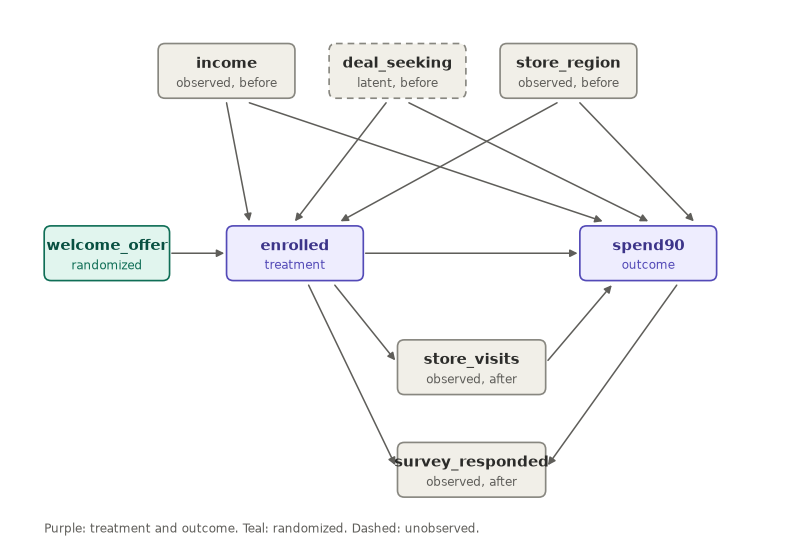

(<Figure size 1000x700 with 1 Axes>, <Axes: >)

In [ ]:
draw_reference_dag()

## Arrow justifications
One short line per arrow, grouped.

**Randomized offer**
- TODO

**Variables that point into both enrollment and spending**
- TODO

**Effects of enrollment**
- TODO

## Arrows I deliberately omitted (and why)
- TODO

In [ ]:
# TODO: sanity checks
#  - is the graph acyclic?
#  - does welcome_offer have any parents?
#  - is there any edge from welcome_offer to spend90?

**Checkpoint B:** every arrow in the plot has a sentence behind it? Yes / No

---
# Part C: Backdoor reasoning

**In my own words:** what is a backdoor path, and why does it matter?

TODO

In [ ]:
paths = backdoor_paths(g, "enrolled", "spend90")
# TODO: print each path in a readable way (e.g., A <- B -> C)

## My by-hand list of backdoor paths
TODO

**Mismatches with the code output (and why):**
TODO

## What is happening on each path?
(For each path: which variable is a confounder, mediator, or collider, if any?)

TODO

## Adjustment set
**Control for:** TODO

**Must NOT control for (and why):** TODO

## The deal_seeking question
If `deal_seeking` is unobserved, can I block every backdoor path? What follows for the naive comparison, and for why the randomized offer is valuable?

TODO

In [ ]:
# TODO (stretch): check your adjustment set with networkx's d-separation tools.
# Hint: the function name differs across networkx versions; check nx.__version__ and the docs.
# Idea: remove the arrows leaving the treatment, then test whether treatment and outcome
#       are separated given your adjustment set.

**Checkpoint C:** by-hand answer and code agree, or I can explain exactly why they don't? Yes / No

---
# Wrap-up

## Key takeaways (plain English, interview-ready)
1. TODO
2. TODO
3. TODO

## Assumptions to log (also add to `docs/assumptions_log.md`)
- Unconfoundedness:
- Overlap:
- SUTVA:
- Randomized offer is an invitation, not a discount:

## Open questions / what Phase 2 needs
- TODO (e.g., which relationships must the simulation build in?)